
<div dir=ltr align=center>

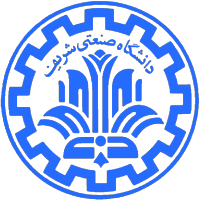

<font color=0F5298 size=7>
Machine Learning <br>
<font color=2565AE size=5>
Computer Engineering Department <br>
Fall 2025 <br>
<font color=3C99D size=5>
    Clustering: K-Means Clustering<br>
<font color=696880 size=4>
    Prepared by Benyamin Ghanbari <br>

<font color=696880 size=2>
    Curated by Alireza Mirshafieian

____

# Student Information

In [1]:
student_number = '402106112'
full_name = 'Amir Mohammad Sharbati'

### Image Segmentation Using K-Means Clustering for Color-Based Region Extraction

### Description: 

In this project, you will implement **K-Means clustering from scratch** and use it to perform image segmentation based on color similarity. **Image segmentation** is the process of dividing an image into meaningful regions. In this assignment, segmentation is done using **color clustering**, where every pixel is grouped into one of K color clusters.

**⚠️ Notice:** You are allowed to use **only the imported libraries** and must **follow the provided function structure**.



# 📝 **Project Instructions**

1. **Load the image**  
   Load the input image and convert it into an **RGB numerical array**.

2. **Reshape image to pixels**  
   Flatten the image into a **2D array**, where each row represents one pixel (**R, G, B**).

3. **Initialize K cluster centers**  
   Randomly select **K pixels** to serve as the starting cluster centers.

4. **Assign pixels to nearest cluster**  
   Compute **distances** and assign each pixel to the **closest cluster center**.

5. **Update cluster centers**  
   Recalculate each center as the **mean color** of all pixels assigned to that cluster.

6. **K-Means algorithm**  
   Repeat **assignment** and **update steps** until **convergence** or **max iterations**.

7. **Reconstruct segmented image**  
   Replace each pixel with the **color of its assigned cluster center**.

8. **Using the Elbow Method**  
   Compute the Compute Within-Cluster Sum of Squares **WCSS** for various **K values** to help estimate an **optimal K**.

9. **Run the segmentation**  
   Apply your **full K-Means pipeline** to segment the chosen image.

10. **Display results**  
    Plot and **visualize** the original and segmented images **side-by-side**.


# 📤 **Expected Output**

- A **segmented image** produced by your **K-Means implementation**  
- A **plot showing the Elbow Method curve** (**WCSS vs. K**)  
- **Observe** how changing **K** affects segmentation


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [25]:
# Step 1: Load the image
def load_image(path):
    image = Image.open(path).convert("RGB")
    data = np.array(image, dtype=float) / 255.0
    return data


# Step 2: Reshape image to pixels: 
def preprocess_image(image_data):
    h, w, c = image_data.shape
    pixels = image_data.reshape(h * w, c)
    return pixels

In [26]:
# Step 3: Initialize K cluster centers
def initialize_centers(pixels, k):
    # randomly pick k unique pixel indices
    index = np.random.choice(len(pixels), size=k, replace=False)
    centers = pixels[index]
    return centers


# Step 4: Assign pixels to nearest cluster
def assign_clusters(pixels, centers):
    # compute distance from every pixel to each center
    distances = np.linalg.norm(pixels[:, None] - centers[None, :], axis=2)
    labels = np.argmin(distances, axis=1)
    return labels


# Step 5: Update cluster centers
def update_centers(pixels, labels, k):
    new_centers = []
    for i in range(k):
        cluster_pixels = pixels[labels == i]
        if len(cluster_pixels) > 0:
            new_centers.append(cluster_pixels.mean(axis=0))
        else: # if a cluster gets empty, reinitialize randomly
            new_centers.append(pixels[np.random.randint(0, len(pixels))])
    return np.array(new_centers)


# Step 6: K-Means algorithm
def kmeans(pixels, k, max_iters=10, tol=1e-4):
    centers = initialize_centers(pixels, k)

    for _ in range(max_iters):
        labels = assign_clusters(pixels, centers)
        new_centers = update_centers(pixels, labels, k)

        # check convergence (center movement)
        shift = np.linalg.norm(new_centers - centers)
        if shift < tol:
            break

        centers = new_centers

    return centers, labels

In [27]:
# Step 7: Reconstruct segmented image
def recreate_image(labels, centers, image_shape):
    h, w, c = image_shape
    segmented = centers[labels]            # replace each pixel with its cluster center
    segmented = segmented.reshape(h, w, c) # reshape back to image
    return segmented

In [28]:
# Step 8: Elbow Method
def calculate_wcss(pixels, max_k=10):
    wcss = []
    for k in range(1, max_k + 1):
        centers, labels = kmeans(pixels, k)
        # sum of squared distances of each pixel to its assigned center
        dist = np.linalg.norm(pixels - centers[labels], axis=1)
        wcss.append(np.sum(dist ** 2))
    return wcss


def plot_elbow(wcss):
    ks = range(1, len(wcss) + 1)
    plt.plot(ks, wcss, marker='o')
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("WCSS")
    plt.title("Elbow Method for Optimal K")
    plt.grid(True)
    
    # Use scientific notation with offset (like 1e7)
    ax = plt.gca()
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    
    plt.show()

In [58]:
# Step 9: Run the segmentation: Call above functions
image_path = 'matryoshka.jpg'
image_data = load_image(image_path)
pixels = preprocess_image(image_data) # Pixels for K-Means (normalized)

# Pixels for WCSS (raw) -> We can also use 'pixels' which are normalized and used in K-Means
pixels_raw = preprocess_image(np.array(Image.open(image_path).convert("RGB"), dtype=float))

k = 5 
centers, labels = kmeans(pixels, k)
segmented = recreate_image(labels, centers, image_data.shape)

# wcss = calculate_wcss(pixels)

# Subsample pixels for WCSS to speed up (Or we can use the line above that I commented it.)
sample_idx = np.random.choice(len(pixels_raw), size=3000, replace=False)
wcss = calculate_wcss(pixels_raw[sample_idx])

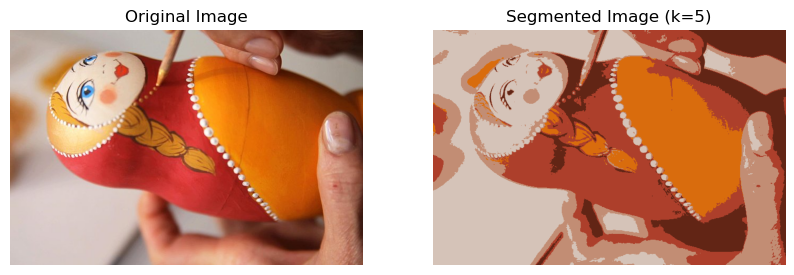

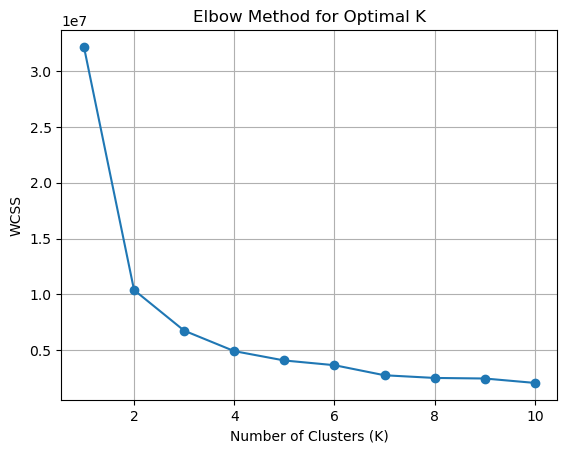

In [59]:
# Step 10: Display results
plt.figure(figsize=(10, 5))

# Original image
plt.subplot(1, 2, 1)
plt.title("Original Image")
original = Image.open(image_path).convert("RGB")
plt.imshow(original)
plt.axis("off")

# Segmented image
plt.subplot(1, 2, 2)
plt.title("Segmented Image (k=5)")
plt.imshow(segmented)
plt.axis("off")

plt.show()

# Plot Elbow Method
plot_elbow(wcss)